# 1. Данные: загрузка, очистка, контроль качества

**Цель ноутбука** — показать путь от сырых выгрузок API до чистой базы и проверить,
можно ли доверять каталогу в научных выводах.

| Источник | Что содержит | Объём |
|---|---|---|
| [USGS Earthquake Catalog](https://earthquake.usgs.gov/fdsnws/event/1/) | все землетрясения мира M ≥ 4.5, 1973–2025 | ~290 тыс. событий |
| [NOAA NCEI Significant Earthquakes](https://www.ngdc.noaa.gov/hazel/view/hazards/earthquake/search) | значимые события: жертвы, ущерб, разрушения | ~4 тыс. |
| [NOAA NCEI Tsunami Events](https://www.ngdc.noaa.gov/hazel/view/hazards/tsunami/event-search) | цунами, высота волны, жертвы | ~1,6 тыс. |

Загрузка: `python -m seismic.download`, очистка и запись в SQLite: `python -m seismic.etl`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from seismic import config, db, etl, plots, regions, stats

plots.setup_style()
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

## 1.1. Сырые данные USGS

In [2]:
raw = pd.read_csv(config.RAW_DIR / "usgs_catalog.csv.gz")
print(f"{len(raw):,} строк, {raw.memory_usage(deep=True).sum() / 1e6:.0f} МБ в памяти")
raw.head()

287,953 строк, 43 МБ в памяти


,time,latitude,longitude,depth,mag,magType,id,place,type
0,1973-01-01T03:46:09.800Z,-9.214,150.634,41.0,5.3,mb,usp0000001,"123 km N of Alotau, Papua New Guinea",earthquake
1,1973-01-01T05:22:29.800Z,-15.012,-173.958,33.0,5.0,mb,usp0000002,"105 km N of Hihifo, Tonga",earthquake
2,1973-01-01T09:28:57.200Z,-22.161,-65.792,205.0,4.8,mb,usp0000003,"21 km WSW of La Quiaca, Argentina",earthquake
3,1973-01-01T11:42:37.500Z,-35.513,-16.211,33.0,6.0,ms,usp0000004,southern Mid-Atlantic Ridge,earthquake
4,1973-01-02T00:53:20.300Z,-9.854,117.427,66.0,5.5,mb,usp0000008,"150 km S of Sumbawa Besar, Indonesia",earthquake


In [3]:
quality = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "пропуски": raw.isna().sum(),
    "пропуски, %": (raw.isna().mean() * 100).round(2),
    "уникальных": raw.nunique(),
})
quality

,тип,пропуски,"пропуски, %",уникальных
time,str,0,0.0,287951
latitude,float64,0,0.0,166578
longitude,float64,0,0.0,191046
depth,float64,2,0.0,32673
mag,float64,0,0.0,183
magType,str,1,0.0,25
id,str,0,0.0,287953
place,str,0,0.0,143137
type,str,0,0.0,7


In [4]:
# В каталоге есть не только землетрясения: взрывы, обрушения в шахтах и т.п.
raw["type"].value_counts()

type
earthquake           287309
nuclear explosion       546
volcanic eruption        71
explosion                16
mine collapse             6
rock burst                3
landslide                 2
Name: count, dtype: int64

**Тип магнитуды** меняется со временем: в 1970-х преобладала mb (по объёмным волнам),
сейчас — моментная магнитуда Mw. mb «насыщается» около 6–6.5, поэтому сильные события
корректно сравнивать только по Mw. Это важно для интерпретации b-value (ноутбук 3).

In [5]:
mag_types = (
    raw.assign(decade=raw["time"].str[:3] + "0-е", mag_type=raw["magType"].str.lower())
    .pivot_table(index="decade", columns="mag_type", values="id", aggfunc="count", fill_value=0)
)
top_types = mag_types.sum().nlargest(5).index
(mag_types[top_types].div(mag_types.sum(axis=1), axis=0) * 100).round(1)

mag_type,mb,mwc,mww,mw,ms
decade,,,,,
1970-е,91.8,0.0,0.0,0.5,7.0
1980-е,83.1,0.0,0.0,11.8,3.9
1990-е,76.9,7.4,0.0,10.6,2.4
2000-е,71.4,22.4,0.0,0.5,0.3
2010-е,82.9,4.8,7.4,0.7,0.0
2020-е,80.3,0.0,16.5,0.2,0.0


## 1.2. Очистка

`etl.clean_usgs` выполняет:
- фильтрацию по `type == "earthquake"` и удаление дублей по `id`;
- разбор времени ISO 8601 в `datetime64[UTC]`;
- классификацию очагов по глубине: мелкофокусные (< 70 км), промежуточные (70–300 км), глубокофокусные (> 300 км);
- извлечение страны/акватории из текстового поля `place` регулярными выражениями;
- отнесение каждого события к сейсмической зоне (векторно, NumPy-масками).

In [6]:
events = etl.clean_usgs(raw)
print(f"после очистки: {len(events):,} событий (удалено {len(raw) - len(events):,})")
events.sample(5, random_state=3)[["time_utc", "mag", "depth_km", "depth_class", "place", "area", "zone_id"]]

после очистки: 287,309 событий (удалено 644)


,time_utc,mag,depth_km,depth_class,place,area,zone_id
203727,2014-10-03 05:36:14.130000+00:00,4.9,125.93,промежуточное,"43 km W of Ambunti, Papua New Guinea",Papua New Guinea,5
75368,1992-12-22 01:13:40.120000+00:00,4.9,42.10,мелкофокусное,"177 km E of Amahai, Indonesia",Indonesia,5
211159,2015-09-29 17:50:14.500000+00:00,5.0,53.10,мелкофокусное,"62 km ESE of Tobelo, Indonesia",Indonesia,4
50895,1987-01-24 19:12:53.060000+00:00,4.6,33.00,мелкофокусное,"125 km SE of Old Harbor, Alaska",Alaska,2
163478,2009-07-21 02:45:00.260000+00:00,4.5,12.00,мелкофокусное,"125 km WSW of Te Anau, New Zealand",New Zealand,6


In [7]:
# Как работает извлечение области из place
(events[["place", "area"]].drop_duplicates("area").sample(8, random_state=11))

,place,area
7766,"3 km NNW of Fayette, Alabama",Alabama
94914,Java Sea,Java Sea
37041,East Timor region,East Timor
128923,Hawaiian Islands region,Hawaiian Islands
112808,Red Sea,Red Sea
83,"47 km SW of Siavonga, Zambia",Zambia
144696,Gulf of Thailand,Gulf of Thailand
20908,Afghanistan-Pakistan border region,Afghanistan-Pakistan border


In [8]:
zones = regions.zones_frame().set_index("zone_id")
zone_counts = events["zone_id"].map(zones["name"]).value_counts()
zone_counts.to_frame("событий").assign(**{"доля, %": (zone_counts / zone_counts.sum() * 100).round(1)})

,событий,"доля, %"
zone_id,,
"Тонга, Фиджи, Вануату, Кермадек",50577,17.6
Прочие (океанические хребты и др.),47963,16.7
Индонезия,33203,11.6
"Япония, Курилы, Камчатка",30785,10.7
Новая Гвинея и Соломоновы о-ва,26860,9.3
"Анды (Чили, Перу, Эквадор)",19670,6.8
Филиппины и Тайвань,17332,6.0
"Гималаи, Центральная Азия, Китай",14168,4.9
Марианские о-ва и Идзу-Бонин,11077,3.9


## 1.3. Полнота каталога

Каталог полон только начиная с некоторой магнитуды **Mc**: более слабые события сеть
станций регистрирует не всегда. Если считать статистику ниже Mc, получим смещённые оценки.
Mc оценивается методом максимальной кривизны (пик некумулятивного распределения + 0.2).

In [9]:
mc_by_period = (
    events.assign(period=pd.cut(events["year"], [1972, 1984, 1994, 2004, 2014, 2025],
                                labels=["1973–84", "1985–94", "1995–2004", "2005–14", "2015–25"]))
    .groupby("period", observed=True)["mag"]
    .agg(n="size", mc=stats.magnitude_of_completeness)
)
mc_by_period

,n,mc
period,,
1973–84,41591,5.0
1985–94,42296,4.9
1995–2004,47792,4.7
2005–14,74115,4.7
2015–25,81515,4.7


До середины 1990-х каталог полон только с M4.9–5.0, затем порог снизился до M4.7 —
сеть станций стала плотнее. Чтобы сравнивать зоны на всём интервале 1973–2025,
в анализе распределений используется консервативный порог **Mc = 5.0**.

## 1.4. Карта эпицентров

Землетрясения M ≥ 6 «прорисовывают» границы литосферных плит. Цвет показывает глубину очага:
глубокие события (тёмные) встречаются только в зонах субдукции, где океаническая плита
погружается в мантию.

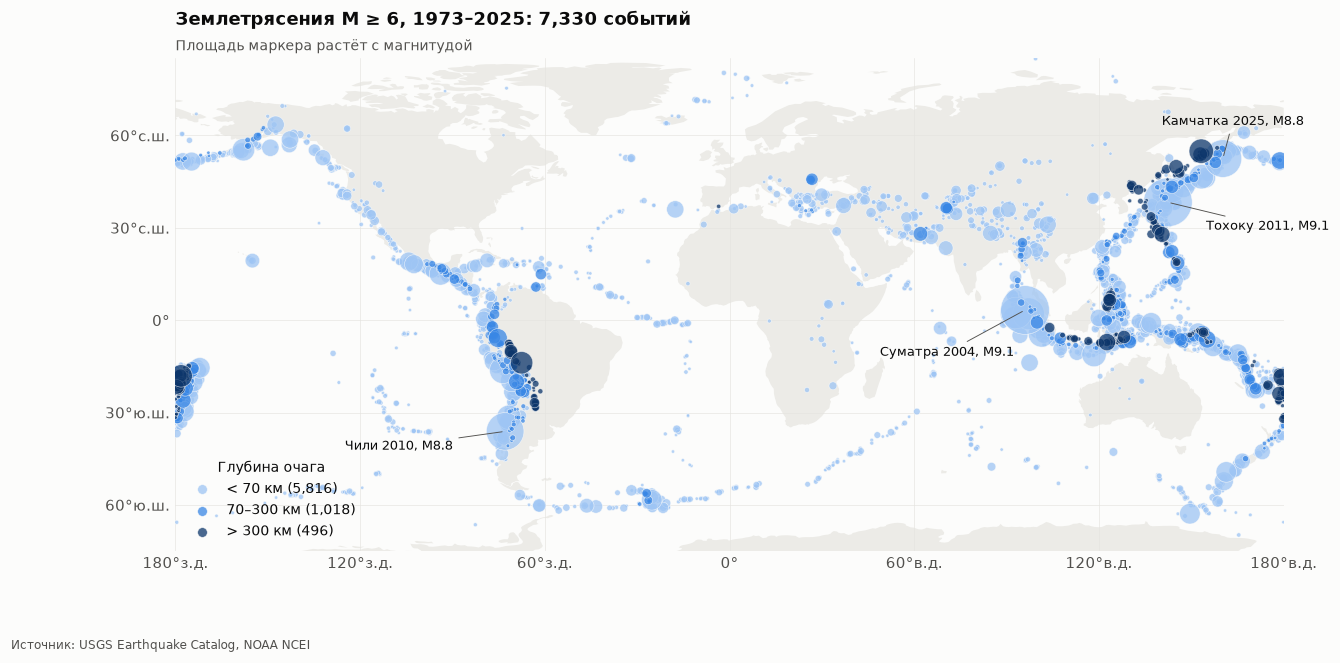

In [10]:
strong = events.loc[events["mag"] >= 6].sort_values("mag")
depth_colors = {"мелкофокусное": plots.BLUE_RAMP[1], "промежуточное": plots.BLUE_RAMP[3],
                "глубокофокусное": plots.BLUE_RAMP[6]}
depth_labels = {"мелкофокусное": "< 70 км", "промежуточное": "70–300 км", "глубокофокусное": "> 300 км"}

fig, ax = plt.subplots(figsize=(13, 5.9))
plots.world_axes(ax)
for cls, color in depth_colors.items():
    sub = strong.loc[strong["depth_class"] == cls]
    ax.scatter(sub["longitude"], sub["latitude"], s=plots.magnitude_size(sub["mag"], base=6) * 4,
               c=color, alpha=0.75, linewidths=0.4, edgecolors=plots.SURFACE,
               label=f"{depth_labels[cls]} ({len(sub):,})")

# подписи ключевых событий со смещениями, подобранными вручную, чтобы не было наложений
callouts = {
    "official20041226005853450_30": ("Суматра 2004, M9.1", (-95, -30)),
    "official20110311054624120_30": ("Тохоку 2011, M9.1", (25, -18)),
    "official20100227063411530_30": ("Чили 2010, M8.8", (-105, -12)),
    "us6000qw60": ("Камчатка 2025, M8.8", (-40, 22)),
}
for event_id, (label, offset) in callouts.items():
    row = strong.loc[strong["event_id"] == event_id].iloc[0]
    ax.annotate(label, (row["longitude"], row["latitude"]), xytext=offset, textcoords="offset points",
                fontsize=8.5, color=plots.TEXT,
                arrowprops=dict(arrowstyle="-", color=plots.TEXT_MUTED, linewidth=0.6))
legend = ax.legend(title="Глубина очага", loc="lower left", fontsize=9, title_fontsize=9)
for handle in legend.legend_handles:
    handle.set_sizes([40])
ax.set_title(f"Землетрясения M ≥ 6, 1973–2025: {len(strong):,} событий")
plots.subtitle(ax, "Площадь маркера растёт с магнитудой")
plots.source_note(fig)
plots.save(fig, "01_world_map")
plt.show()

## 1.5. Связь каталогов USGS и NOAA

В NOAA нет идентификаторов USGS, поэтому события сопоставлены по времени (±90 с,
`pd.merge_asof`), расстоянию между эпицентрами (≤ 150 км, формула гаверсинусов) и разнице
магнитуд (≤ 0.8). Это позволяет в SQL спрашивать «какая доля землетрясений M ≥ 7 привела
к жертвам».

In [11]:
linked = db.query("""
    SELECT (year / 10) * 10 AS decade,
           COUNT(*) AS noaa_events,
           SUM(usgs_event_id IS NOT NULL) AS linked,
           ROUND(100.0 * SUM(usgs_event_id IS NOT NULL) / COUNT(*), 1) AS linked_pct
    FROM significant
    WHERE year >= 1973 AND mag >= 4.5
    GROUP BY decade
""")
linked

,decade,noaa_events,linked,linked_pct
0,1970,201,198,98.5
1,1980,310,307,99.0
2,1990,325,324,99.7
3,2000,561,555,98.9
4,2010,562,558,99.3
5,2020,240,240,100.0


Почти все значимые события с M ≥ 4.5 после 1973 года нашли пару в каталоге USGS.
Несопоставленные — в основном события без точного времени или с сильно различающимися
магнитудами в двух агентствах.

**Вывод:** данные чистые и связанные; ограничения (смена типа магнитуды, Mc ≈ 4.7)
учтены в дальнейшем анализе.